<a href="https://colab.research.google.com/github/Mohtasir/Disease-Prediction/blob/main/DiseasePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# !pip install xgboost   # uncomment if xgboost is not installed (Colab usually has it)

import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()

# In sklearn: 0 = malignant, 1 = benign. Flip it so 1 = disease (malignant)
y = 1 - data.target
class_names = ["Benign", "Malignant"]

print("Shape:", X.shape)
X.head()

Shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Missing values: 0

Class distribution:
  Benign    : 357 (62.7%)
  Malignant : 212 (37.3%)


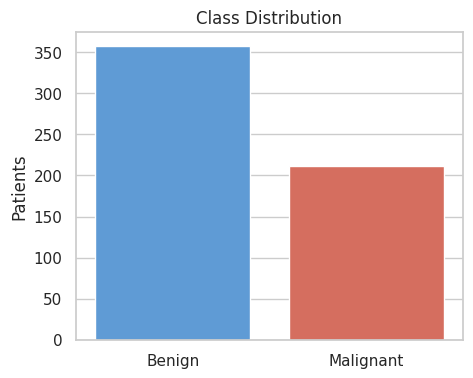

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


In [ ]:
print("Missing values:", int(X.isna().sum().sum()))
print("\nClass distribution:")
counts = y.value_counts().sort_index()
for cls, n in counts.items():
    print(f"  {class_names[cls]:<10}: {n} ({n/len(y):.1%})")

plt.figure(figsize=(5, 4))
sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values,
            palette=["#4c9be8", "#e8604c"])
plt.title("Class Distribution")
plt.ylabel("Patients")
plt.show()

X.describe().T.round(2)

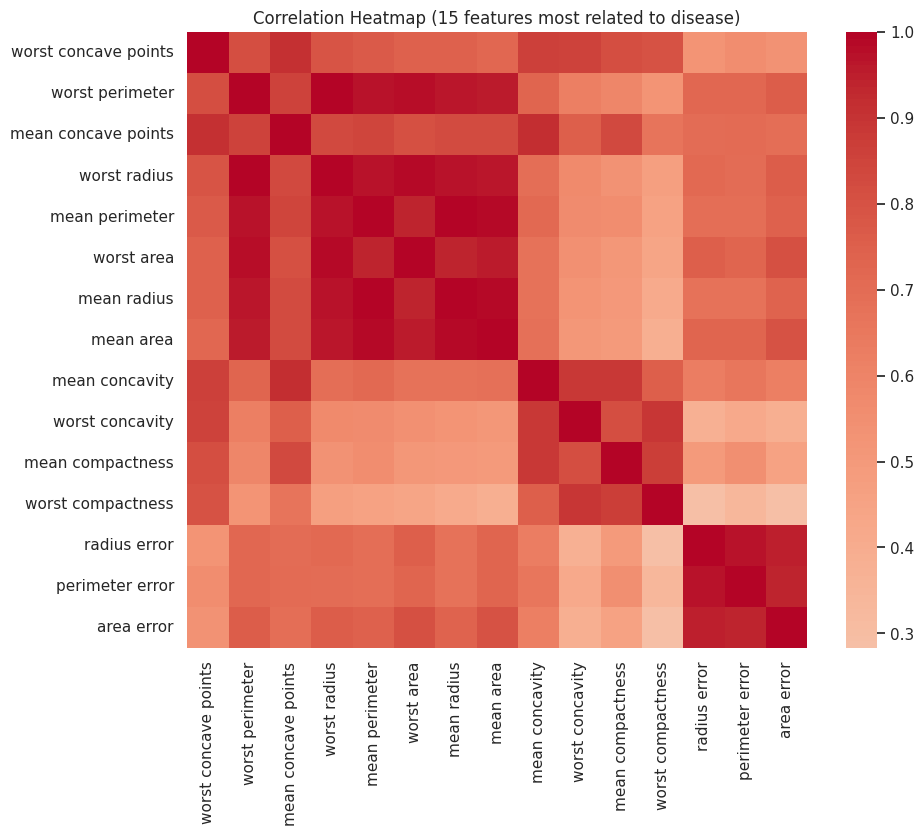

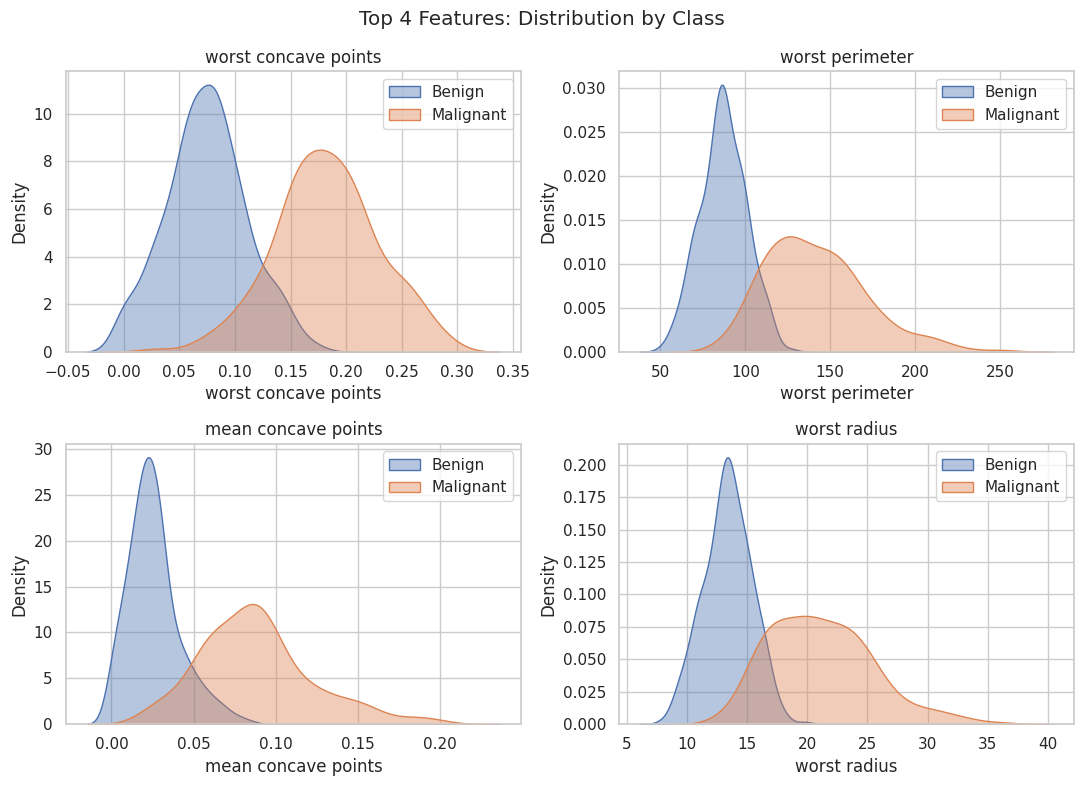

In [ ]:
corr_with_target = X.corrwith(y).abs().sort_values(ascending=False)

# Heatmap of the 15 features most related to the disease
top15 = corr_with_target.head(15).index
plt.figure(figsize=(10, 8))
sns.heatmap(X[top15].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (15 features most related to disease)")
plt.show()

# Distribution of the 4 most informative features by class
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), corr_with_target.head(4).index):
    for cls in [0, 1]:
        sns.kdeplot(X.loc[y == cls, feat], ax=ax, fill=True, alpha=0.4, label=class_names[cls])
    ax.set_title(feat)
    ax.legend()
plt.suptitle("Top 4 Features: Distribution by Class")
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 455 | Test size: 114


In [ ]:
def make_pipeline(clf):
    # Fit imputer and scaler only on training folds, so no data leakage
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", clf),
    ])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": (
        make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
        {"clf__C": [0.01, 0.1, 1, 10, 100]},
    ),
    "SVM": (
        make_pipeline(SVC(probability=True, random_state=RANDOM_STATE)),
        {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"], "clf__gamma": ["scale", 0.01]},
    ),
    "Random Forest": (
        make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 5, 10],
         "clf__min_samples_leaf": [1, 3]},
    ),
    "XGBoost": (
        make_pipeline(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE,
                                    scale_pos_weight=scale_pos_weight)),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5],
         "clf__learning_rate": [0.05, 0.1]},
    ),
}

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]

fitted, cv_scores, results = {}, {}, []

for name, (pipeline, grid) in models.items():
    print(f"--> {name}")
    search = GridSearchCV(pipeline, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    fitted[name] = best
    print("    Best params:", search.best_params_)
    print(f"    CV ROC-AUC : {search.best_score_:.4f}")

    # 5-fold cross-validation with several metrics
    cvres = cross_validate(best, X_train, y_train, cv=cv, scoring=metric_names)
    cv_scores[name] = {m: cvres[f"test_{m}"] for m in metric_names}

    # Evaluation on the hold-out test set
    y_pred = best.predict(X_test)
    y_proba = best.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "CV ROC-AUC (mean)": cv_scores[name]["roc_auc"].mean(),
        "CV ROC-AUC (std)": cv_scores[name]["roc_auc"].std(),
    })

--> Logistic Regression
    Best params: {'clf__C': 1}
    CV ROC-AUC : 0.9958
--> SVM
    Best params: {'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}
    CV ROC-AUC : 0.9954
--> Random Forest
    Best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
    CV ROC-AUC : 0.9890
--> XGBoost
    Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 300}
    CV ROC-AUC : 0.9943


In [ ]:
results_df = (pd.DataFrame(results)
              .sort_values(["ROC-AUC", "Recall"], ascending=False)
              .reset_index(drop=True))
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
0,SVM,0.9825,1.000,0.9524,0.9756,0.9960,0.9954,0.0053
1,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960,0.9958,0.0047
2,XGBoost,0.9649,1.000,0.9048,0.9500,0.9934,0.9943,0.0029
3,Random Forest,0.9737,1.000,0.9286,0.9630,0.9929,0.9890,0.0068


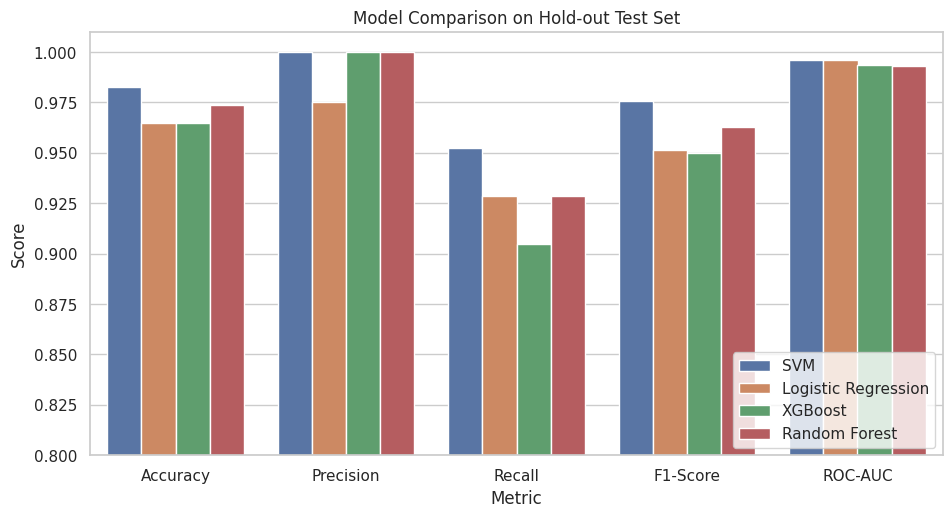

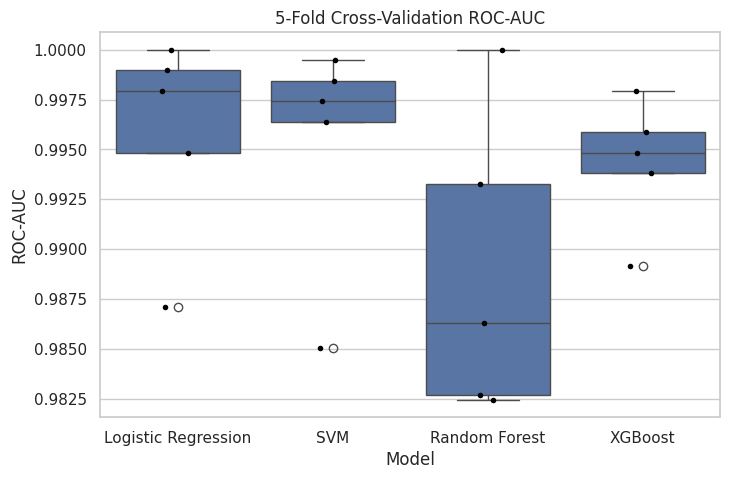

In [ ]:
# Metric comparison on the test set
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
melted = results_df.melt(id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score")

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=melted, x="Metric", y="Score", hue="Model")
ax.set_ylim(0.8, 1.01)
plt.title("Model Comparison on Hold-out Test Set")
plt.legend(loc="lower right")
plt.show()

# Cross-validation stability
rows = [{"Model": m, "ROC-AUC": s} for m, d in cv_scores.items() for s in d["roc_auc"]]
cv_df = pd.DataFrame(rows)
plt.figure(figsize=(8, 5))
sns.boxplot(data=cv_df, x="Model", y="ROC-AUC")
sns.stripplot(data=cv_df, x="Model", y="ROC-AUC", color="black", size=4)
plt.title("5-Fold Cross-Validation ROC-AUC")
plt.show()

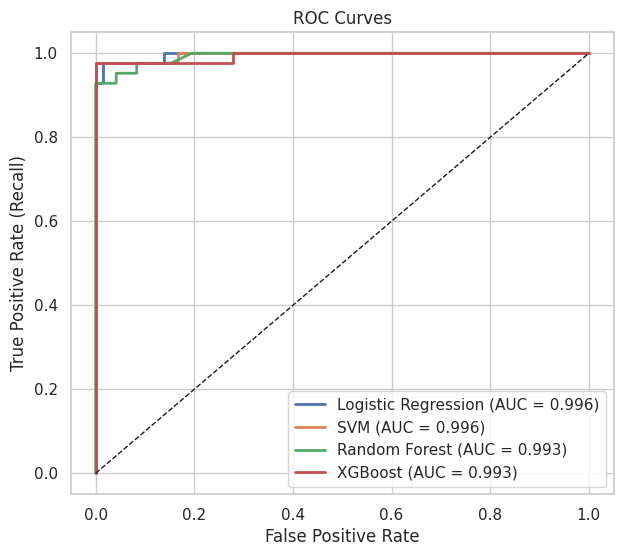

In [ ]:
plt.figure(figsize=(7, 6))
for name, model in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.show()

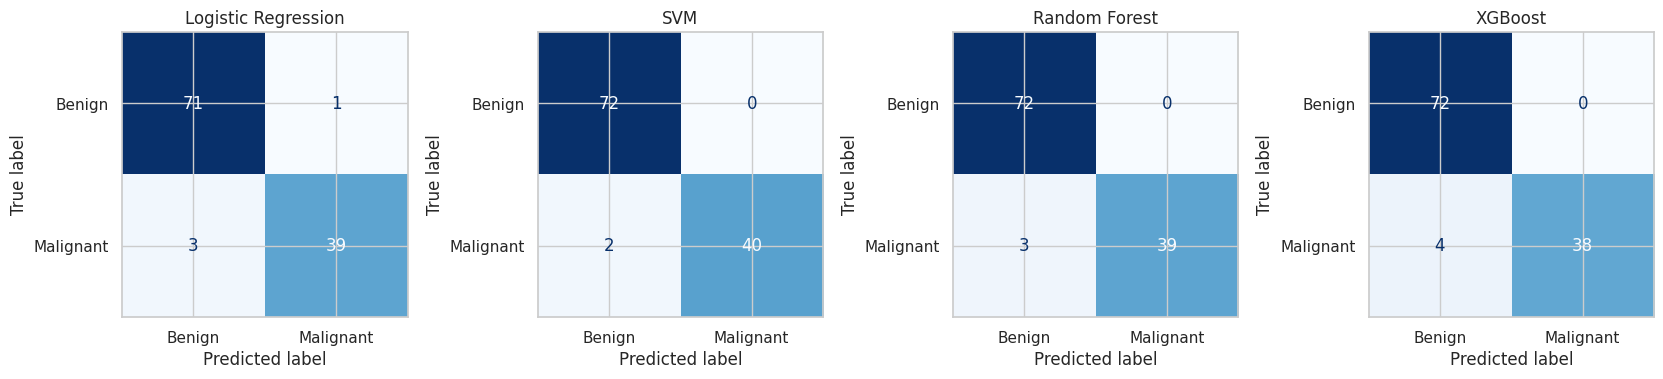

In [ ]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4.2 * len(fitted), 4))
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

BEST MODEL: SVM 

              precision    recall  f1-score   support

      Benign     0.9730    1.0000    0.9863        72
   Malignant     1.0000    0.9524    0.9756        42

    accuracy                         0.9825       114
   macro avg     0.9865    0.9762    0.9810       114
weighted avg     0.9829    0.9825    0.9824       114



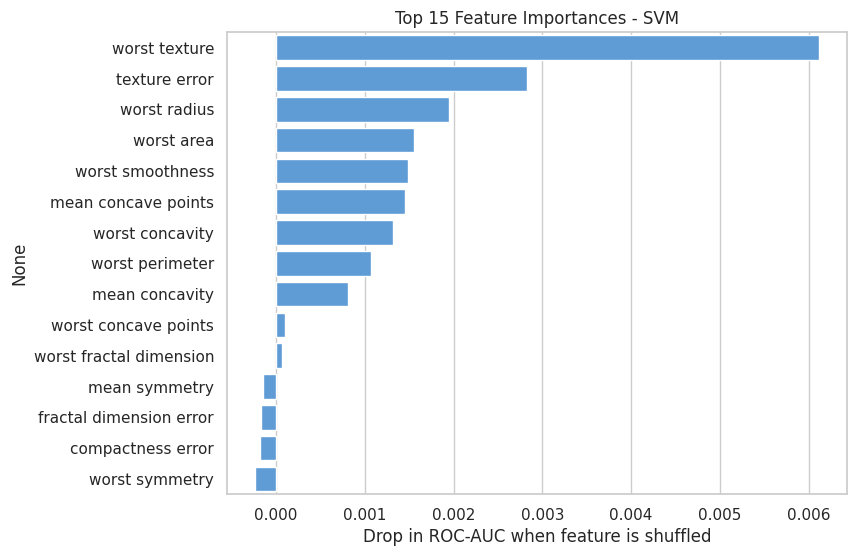

In [ ]:
best_name = results_df.loc[0, "Model"]
best_model = fitted[best_name]
print("BEST MODEL:", best_name, "\n")
print(classification_report(y_test, best_model.predict(X_test), target_names=class_names, digits=4))

# Permutation importance (works for any model)
result = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(result.importances_mean, index=X.columns)
       .sort_values(ascending=False).head(15))

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color="#4c9be8")
plt.title(f"Top 15 Feature Importances - {best_name}")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.show()

In [ ]:
# Save the best model
joblib.dump({"model": best_model, "features": list(X.columns),
             "class_names": class_names, "name": best_name}, "best_model.joblib")

def predict_patient(patient_dict, model_path="best_model.joblib", threshold=0.5):
    bundle = joblib.load(model_path)
    row = pd.DataFrame([patient_dict]).reindex(columns=bundle["features"])
    proba = float(bundle["model"].predict_proba(row)[0, 1])
    return {"probability_of_disease": round(proba, 4),
            "prediction": bundle["class_names"][int(proba >= threshold)]}

# Demo with the first patient from the test set
sample = X_test.iloc[0].to_dict()
print(predict_patient(sample))
print("Actual label:", class_names[int(y_test.iloc[0])])

{'probability_of_disease': 0.0005, 'prediction': 'Benign'}
Actual label: Benign
